In [25]:
from pathlib import Path
from collections import Counter
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = Path("/trinity/home/glebsolyanik03/Real-ESRGAN/datasets/BC-MultiSet-50")

IMG_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

# номера классов в масках — СВЕРЬ с types.csv / README датасета
CLASS_NAMES = {1: "Tumor", 2: "Fibroblast", 3: "Inflammatory"}
CLASS_COLORS = {1: (255, 0, 0), 2: (0, 200, 0), 3: (0, 120, 255)}  # RGB

In [26]:
def show_tree(root, max_depth=3, depth=0):
    """Печатает папки и сколько в каждой файлов каждого типа."""
    if depth > max_depth:
        return
    files = [p for p in root.iterdir() if p.is_file()]
    dirs = sorted(p for p in root.iterdir() if p.is_dir())
    exts = Counter(p.suffix.lower() for p in files)
    info = ", ".join(f"{n}×{e or '(без расш.)'}" for e, n in exts.most_common())
    print("  " * depth + f"{root.name}/  {info}")
    for p in files:
        if p.suffix.lower() in {".csv", ".xlsx", ".xls", ".json", ".txt", ".md"}:
            print("  " * (depth + 1) + f"- {p.name}")
    for d in dirs:
        show_tree(d, max_depth, depth + 1)

show_tree(dataset_path)

BC-MultiSet-50/  1×.txt, 1×.xlsx
  - class_weights.txt
  - BC-MultiSet.xlsx
  fold1/  1×.csv
    - types.csv
    images/  1500×.png
    labels/  1500×.npy
  fold2/  1×.csv
    - types.csv
    images/  1386×.png
    labels/  1386×.npy
  fold3/  1×.csv
    - types.csv
    images/  1554×.png
    labels/  1554×.npy
  fold4/  1×.csv
    - types.csv
    images/  1151×.png
    labels/  1151×.npy


In [27]:
types_files = sorted(dataset_path.rglob("types.csv"))
print("types.csv:", [str(p.relative_to(dataset_path)) for p in types_files])

types_df = pd.concat(
    [pd.read_csv(p).assign(fold=p.parent.name) for p in types_files],
    ignore_index=True,
) if types_files else None
if types_df is not None:
    print(types_df.shape)
    display(types_df.head())

clin_files = [p for p in dataset_path.rglob("*")
              if p.suffix.lower() in {".xlsx", ".xls", ".csv"} and p.name != "types.csv"]
print("другие таблицы:", [str(p.relative_to(dataset_path)) for p in clin_files])

clinical_df = None
for p in clin_files:
    df = pd.read_excel(p) if p.suffix.lower() in {".xlsx", ".xls"} else pd.read_csv(p)
    print(f"\n{p.name}: {df.shape}")
    display(df.head())
    if clinical_df is None:
        clinical_df = df

types.csv: ['fold1/types.csv', 'fold2/types.csv', 'fold3/types.csv', 'fold4/types.csv']
(5591, 3)


,img,type,fold
0,15866_Crop_10_y0_x0.png,Breast,fold1
1,15866_Crop_10_y0_x192.png,Breast,fold1
2,15866_Crop_10_y0_x384.png,Breast,fold1
3,15866_Crop_10_y0_x576.png,Breast,fold1
4,15866_Crop_10_y192_x0.png,Breast,fold1


другие таблицы: ['BC-MultiSet.xlsx']

BC-MultiSet.xlsx: (50, 16)


,ID,ER_bin,PR_bin,HER2_bin,Nod_bin,MOLT_bin,Age,ER,PR,HER2,Ki67,IIA,TNM,Molecular subtype (MOLT),Grade,TILs(%)
0,473,1,1,1,0,0,38,7,6,3+,93,IIA,T2N0M0,Luminal B+,2,5.0
1,1928,1,1,0,0,0,55,8,4,1+,62,IIA,T2N0M0,Luminal B-,3,1.0
2,1986,0,0,1,1,1,60,0,0,3+,55,IIIC,T2N3M0,HER2-enriched,2,1.0
3,2271,1,1,0,1,0,48,8,6,1+,73,IIB,T2N1M0,Luminal B-,3,1.0
4,2811,1,1,0,0,0,56,8,7,1+,28,IA,T1сN0M0,Luminal B-,2,5.0


In [28]:
images = {p.stem: p for p in dataset_path.rglob("*") if p.suffix.lower() in IMG_EXTS}
masks = {p.stem: p for p in dataset_path.rglob("*.npy")}

print(f"картинок: {len(images)}, npy: {len(masks)}")
print("пример имён картинок:", list(images)[:3])
print("пример имён npy:     ", list(masks)[:3])

pairs = sorted(set(images) & set(masks))
print(f"совпало по имени: {len(pairs)}")

картинок: 5591, npy: 5591
пример имён картинок: ['38153_Crop_8_y192_x192', '26779_Crop_9_y192_x576', '15866_Crop_8_y192_x768']
пример имён npy:      ['6026_Crop_3_y576_x192', '6026_Crop_7_y576_x576', '15866_Crop_10_y384_x0']
совпало по имени: 5591


In [29]:
def load_mask(path):
    """Возвращает (inst_map, type_map): номер ядра и класс для каждого пикселя."""
    m = np.load(path, allow_pickle=True)

    # вариант A: словарь внутри npy
    if m.dtype == object:
        d = m.item()
        inst = next(d[k] for k in d if "inst" in k.lower())
        typ = next(d[k] for k in d if "type" in k.lower() or "class" in k.lower())
        return inst.astype(np.int32), typ.astype(np.int32)

    # вариант B: (H, W, 2) — канал с номерами ядер + канал с классами
    if m.ndim == 3 and m.shape[-1] == 2:
        a, b = m[..., 0], m[..., 1]
        inst, typ = (a, b) if a.max() >= b.max() else (b, a)  # у классов значения маленькие
        return inst.astype(np.int32), typ.astype(np.int32)

    # вариант C: (H, W, K) — отдельный канал на класс (как в PanNuke)
    if m.ndim == 3:
        inst = np.zeros(m.shape[:2], np.int32)
        typ = np.zeros(m.shape[:2], np.int32)
        next_id = 1
        for c in range(m.shape[-1]):
            ch = m[..., c]
            ids = [i for i in np.unique(ch) if i != 0]
            if len(ids) == 0 or (ch.max() == 1 and ch.mean() > 0.5):  # пропуск канала фона
                continue
            for i in ids:
                sel = ch == i
                inst[sel] = next_id
                typ[sel] = c + 1
                next_id += 1
        return inst, typ

    # вариант D: (H, W) — только номера ядер, без классов
    return m.astype(np.int32), (m > 0).astype(np.int32)

# проверим на одном примере
k = pairs[0]
raw = np.load(masks[k], allow_pickle=True)
print("сырой npy:", raw.dtype, getattr(raw, "shape", None))
inst, typ = load_mask(masks[k])
print("ядер:", len(np.unique(inst)) - 1, "| классы:", np.unique(typ))

сырой npy: object ()
ядер: 19 | классы: [0 1 2]


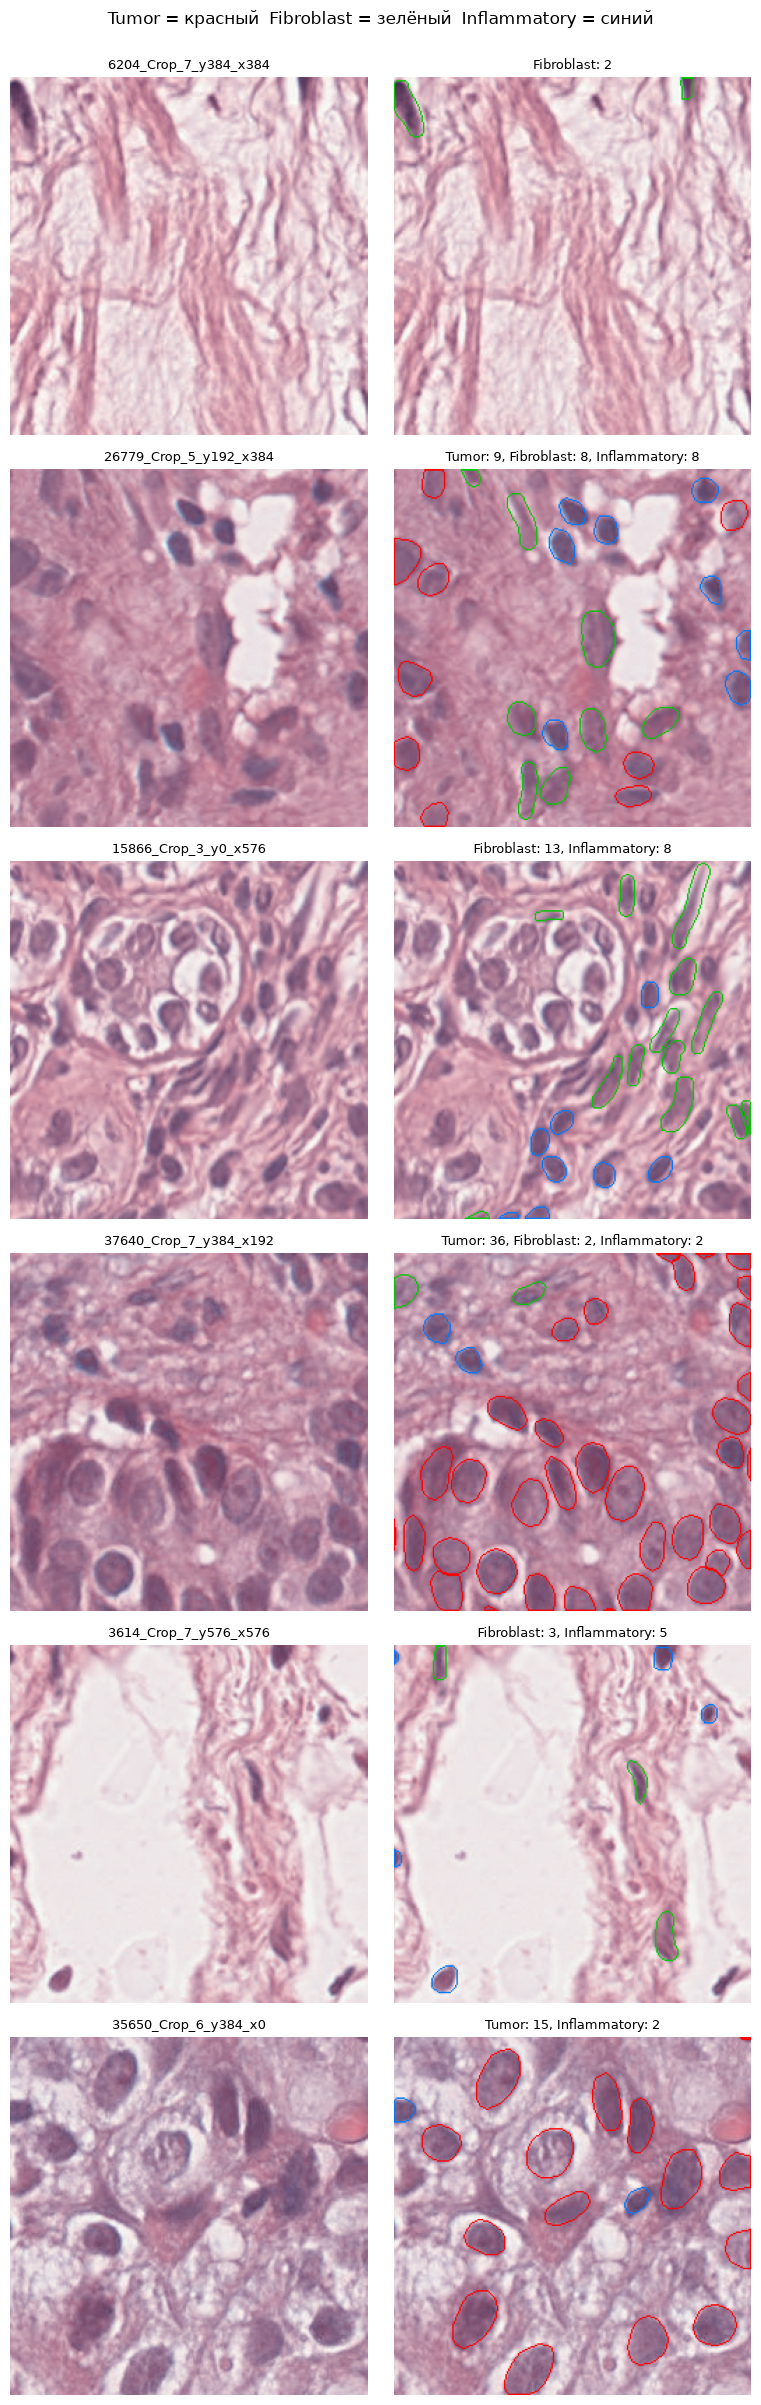

In [30]:
def read_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)

def overlay(img, inst, typ):
    out = img.copy()
    for i in np.unique(inst):
        if i == 0:
            continue
        mask = (inst == i).astype(np.uint8)
        cls = int(np.bincount(typ[mask.astype(bool)]).argmax())
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(out, cnts, -1, CLASS_COLORS.get(cls, (255, 255, 255)), 1)
    return out

N, SEED = 6, 42
random.seed(SEED)
sample = random.sample(pairs, min(N, len(pairs)))

fig, axes = plt.subplots(len(sample), 2, figsize=(8, 4 * len(sample)))
axes = np.atleast_2d(axes)
for row, k in zip(axes, sample):
    img = read_rgb(images[k])
    inst, typ = load_mask(masks[k])
    counts = Counter()
    for i in np.unique(inst)[1:]:
        counts[int(np.bincount(typ[inst == i]).argmax())] += 1
    title = ", ".join(f"{CLASS_NAMES.get(c, c)}: {n}" for c, n in sorted(counts.items()))

    row[0].imshow(img); row[0].set_title(k, fontsize=9)
    row[1].imshow(overlay(img, inst, typ)); row[1].set_title(title, fontsize=9)
    for ax in row:
        ax.axis("off")

legend = "  ".join(f"{n} = {['красный','зелёный','синий'][c-1]}" for c, n in CLASS_NAMES.items())
fig.suptitle(legend, y=1.0)
plt.tight_layout()
plt.show()

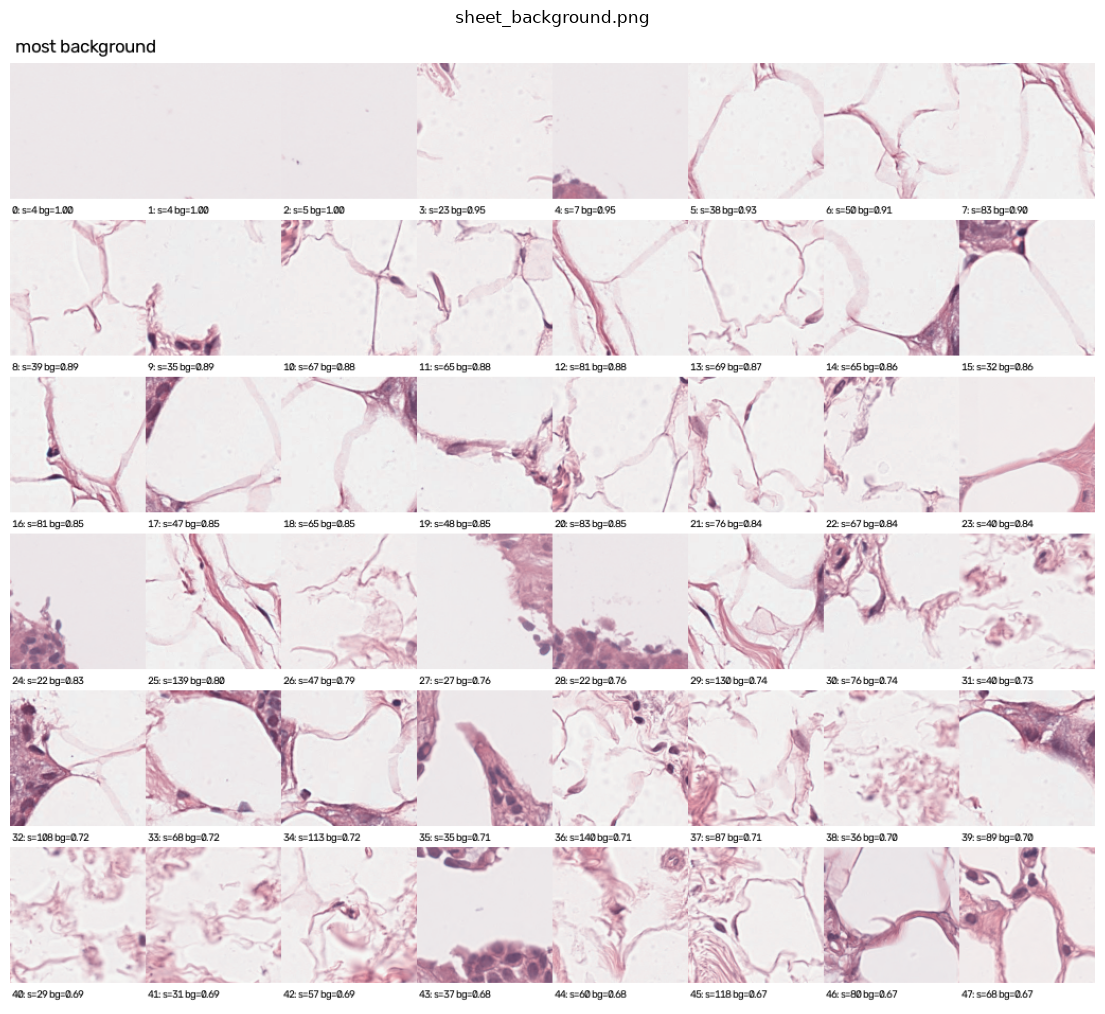

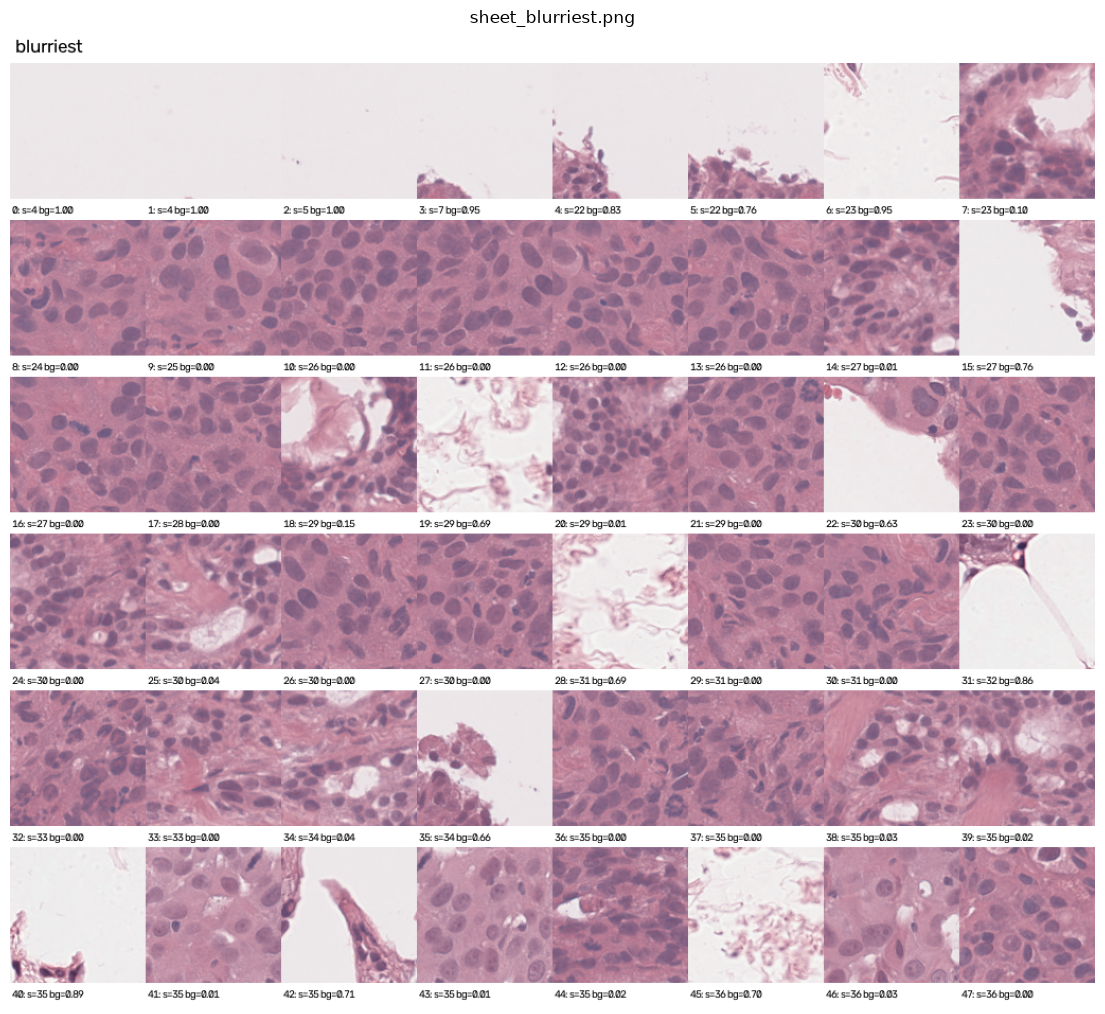

In [ ]:
analysis_path = "/trinity/home/glebsolyanik03/Real-ESRGAN/analysis/BC-MultiSet-50"

analysis_images = ["sheet_background.png", "sheet_blurriest.png", "sheet_sharpest.png"]

for name in analysis_images:
    plt.figure(figsize=(14, 14))
    plt.imshow(read_rgb(analysis_path + "/" + name))
    plt.title(name)
    plt.axis("off")
    plt.show()